# 计算机视觉与OpenCV

本笔记本是 [AI for Beginners Curriculum](http://aka.ms/ai-beginners) 的一部分。

[OpenCV](https://opencv.org/) 被认为是图像处理领域的*事实标准*。它包含许多实用的算法，这些算法是用C++实现的。你也可以通过Python调用OpenCV。

在本笔记本中，我们将为你提供一些使用OpenCV的示例。更多详细信息，你可以访问 [Learn OpenCV](https://learnopencv.com/getting-started-with-opencv/) 在线课程。

首先，让我们 `import cv2`，以及一些其他有用的库：


In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def display_images(l,titles=None,fontsize=12):
    n=len(l)
    fig,ax = plt.subplots(1,n)
    for i,im in enumerate(l):
        ax[i].imshow(im)
        ax[i].axis('off')
        if titles is not None:
            ax[i].set_title(titles[i],fontsize=fontsize)
    fig.set_size_inches(fig.get_size_inches()*n)
    plt.tight_layout()
    plt.show()


## 加载图像

在 Python 中，图像可以方便地用 NumPy 数组表示。例如，一个大小为 320x200 像素的灰度图像会存储在一个 200x320 的数组中，而相同尺寸的彩色图像则会有一个形状为 200x320x3 的数组（对应 3 个颜色通道）。

让我们从加载一张图像开始：


(242, 531, 3)


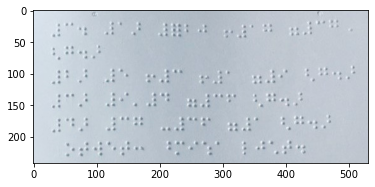

In [2]:
im = cv2.imread('data/braille.jpeg')
print(im.shape)
plt.imshow(im)

正如你所看到的，这是一张盲文的图像。由于我们对实际颜色不是很感兴趣，我们可以将其转换为黑白：


In [98]:
bw_im = cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)
print(bw_im.shape)
plt.imshow(bw_im, cmap='gray')

(242, 531)


## 盲文图像处理

如果我们想应用图像分类来识别文本，就需要将单个符号剪切出来，使其类似于我们之前看到的 MNIST 图像。这可以通过 [目标检测](../11-ObjectDetection/README.md) 技术来实现，我们稍后会讨论这一点，但我们也可以尝试使用纯计算机视觉来完成这一任务。关于如何使用计算机视觉进行字符分离的一个很好的描述可以在 [这篇博客文章](https://learnopencv.com/image-alignment-feature-based-using-opencv-c-python/) 中找到——这里我们将仅关注一些计算机视觉技术。

首先，让我们尝试稍微增强一下图像。我们可以使用 **阈值处理** 的方法（在 [这篇 OpenCV 文章](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html) 中有详细描述）：


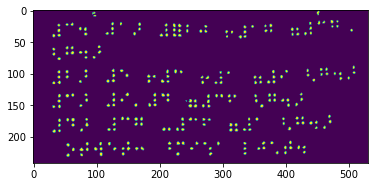

In [99]:
im = cv2.blur(bw_im,(3,3))
im = cv2.adaptiveThreshold(im, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                           cv2.THRESH_BINARY_INV, 5, 4)
im = cv2.medianBlur(im, 3)
_,im = cv2.threshold(im, 0, 255, cv2.THRESH_OTSU)
im = cv2.GaussianBlur(im, (3,3), 0)
_,im = cv2.threshold(im, 0, 255, cv2.THRESH_OTSU)
plt.imshow(im)

要处理图像，我们需要“提取”单个点，即将图像转换为单个点的坐标集。我们可以使用**特征提取**技术来实现，例如 SIFT、SURF 或 [ORB](https://docs.opencv.org/4.x/d1/d89/tutorial_py_orb.html)：


In [100]:
orb = cv2.ORB_create(5000)
f,d = orb.detectAndCompute(im,None)
print(f"First 5 points: { [f[i].pt for i in range(5)]}")

First 5 points: [(307.20001220703125, 40.80000305175781), (297.6000061035156, 114.00000762939453), (423.6000061035156, 133.20001220703125), (242.40000915527344, 144.0), (103.68000793457031, 57.60000228881836)]


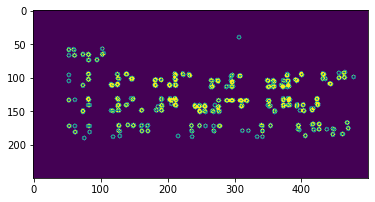

In [109]:
def plot_dots(dots):
    img = np.zeros((250,500))
    for x in dots:
        cv2.circle(img,(int(x[0]),int(x[1])),3,(255,0,0))
    plt.imshow(img)

pts = [x.pt for x in f]
plot_dots(pts)  

要分隔单个字符，我们需要知道整个文本的边界框。要找到它，我们只需计算最小和最大坐标：


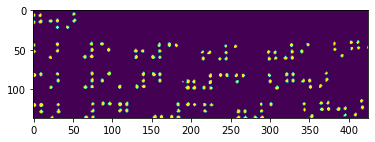

In [120]:
min_x, min_y, max_x, max_y = [int(f([z[i] for z in pts])) for f in (min,max) for i in (0,1)]
min_y+=13
plt.imshow(im[min_y:max_y,min_x:max_x])

此外，此文本可能会部分旋转，为了使其完美对齐，我们需要进行所谓的**透视变换**。我们将采用由点$(x_{min},y_{min}), (x_{min},y_{max}), (x_{max},y_{min}), (x_{max},y_{max})$定义的矩形，并将其与具有相同比例尺寸的新图像对齐：


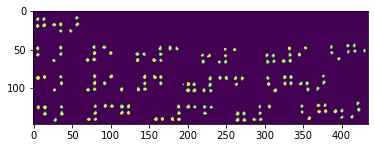

In [122]:
off = 5
src_pts = np.array([(min_x-off,min_y-off),(min_x-off,max_y+off),
                    (max_x+off,min_y-off),(max_x+off,max_y+off)])
w = int(max_x-min_x+off*2)
h = int(max_y-min_y+off*2)
dst_pts = np.array([(0,0),(0,h),(w,0),(w,h)])
ho,m = cv2.findHomography(src_pts,dst_pts)
trim = cv2.warpPerspective(im,ho,(w,h))
plt.imshow(trim)

在我们得到这张对齐良好的图像后，将其切成几块应该相对容易：


In [164]:
char_h = 36
char_w = 24
def slice(img):
    dy,dx = img.shape
    y = 0
    while y+char_h<dy:
        x=0
        while x+char_w<dx:
            # Skip empty lines
            if np.max(img[y:y+char_h,x:x+char_w])>0:
                yield img[y:y+char_h,x:x+char_w]
            x+=char_w
        y+=char_h

sliced = list(slice(trim))
display_images(sliced)

您已经看到，许多任务可以仅通过纯图像处理完成，而无需任何人工智能。如果我们可以使用计算机视觉技术来简化神经网络的工作，我们绝对应该这样做，因为这将使我们能够用更少的训练数据解决问题。


## 使用帧差进行运动检测

在视频流中检测运动是一项非常常见的任务。例如，当监控摄像头捕捉到某些事件时，它可以向我们发送警报。如果我们想了解摄像头中发生了什么，可以使用神经网络进行分析——但在知道有事件发生的情况下，使用神经网络的成本会更低。

运动检测的核心思想非常简单。如果摄像头是固定的，那么摄像头捕获的帧应该彼此非常相似。由于帧是以数组形式表示的，只需对两个连续帧的数组进行相减，就可以得到像素差异。对于静态帧，这种差异应该很小，而当图像中出现显著运动时，差异会变大。

我们将从学习如何打开视频并将其转换为帧序列开始：


In [42]:
vid = cv2.VideoCapture('data/motionvideo.mp4')

c = 0
frames = []
while vid.isOpened():
    ret, frame = vid.read()
    if not ret:
        break
    frames.append(frame)
    c+=1
vid.release()
print(f"Total frames: {c}")
display_images(frames[::150])

Total frames: 876


由于颜色对运动检测并不是那么重要，我们将把所有帧转换为灰度图像。然后，我们将计算帧差异，并绘制它们的范数，以直观地查看活动的数量：


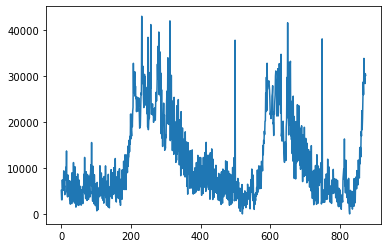

In [56]:
bwframes = [cv2.cvtColor(x,cv2.COLOR_BGR2GRAY) for x in frames]
diffs = [(p2-p1) for p1,p2 in zip(bwframes[:-1],bwframes[1:])]
diff_amps = np.array([np.linalg.norm(x) for x in diffs])
plt.plot(diff_amps)
display_images(diffs[::150],titles=diff_amps[::150])

假设我们想创建一个报告，通过每次发生事件时显示合适的图像来展示摄像机前发生的事情。为此，我们可能需要找出“事件”的开始帧和结束帧，并显示中间帧。为了去除一些噪声，我们还将使用移动平均函数来平滑上方的曲线：


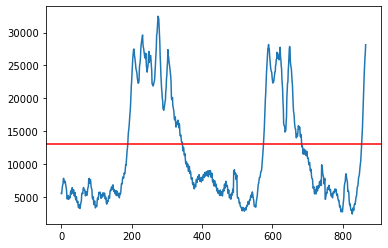

In [57]:
def moving_average(x, w):
    return np.convolve(x, np.ones(w), 'valid') / w

threshold = 13000

plt.plot(moving_average(diff_amps,10))
plt.axhline(y=threshold, color='r', linestyle='-')

现在我们可以使用 `np.where` 找出变化量高于阈值的帧，并提取长度超过30帧的连续帧序列：


In [149]:
active_frames = np.where(diff_amps>threshold)[0]

def subsequence(seq,min_length=30):
    ss = []
    for i,x in enumerate(seq[:-1]):
        ss.append(x)
        if x+1 != seq[i+1]:
            if len(ss)>min_length:
                return ss
            ss.clear()

sub = subsequence(active_frames)
print(sub)


[195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322]


最后，我们可以显示图像：


In [150]:
plt.imshow(frames[(sub[0]+sub[-1])//2])

您可能会注意到这张图片的配色方案看起来不对！这是因为出于历史原因，OpenCV加载图像时使用的是BGR颜色空间，而matplotlib使用的是更传统的RGB颜色顺序。大多数情况下，在加载图像后立即将其转换为RGB是有意义的。


In [151]:
plt.imshow(cv2.cvtColor(frames[(sub[0]+sub[-1])//2],cv2.COLOR_BGR2RGB))

## 使用光流提取运动

仅仅比较两个连续帧可以让我们看到变化的程度，但无法提供关于实际移动的内容以及位置的信息。为了获取这些信息，有一种技术叫做 **[光流](https://docs.opencv.org/3.4/d4/dee/tutorial_optical_flow.html)**：

* **稠密光流** 计算每个像素的运动矢量场，显示它的移动方向
* **稀疏光流** 基于图像中的一些显著特征（例如边缘），并从帧到帧构建它们的轨迹。

可以在 [这个优秀的教程](https://learnopencv.com/optical-flow-in-opencv/) 中了解更多关于光流的内容。

让我们计算帧之间的稠密光流：


In [152]:
flows = [cv2.calcOpticalFlowFarneback(f1, f2, None, 0.5, 3, 15, 3, 5, 1.2, 0) 
         for f1,f2 in zip(bwframes[:-1],bwframes[1:])]
flows[0].shape

(180, 320, 2)

如你所见，对于每一帧，光流具有与帧相同的维度，并且包含两个通道，分别对应光流向量的 x 和 y 分量。

在二维中显示光流有些困难，但我们可以使用一个巧妙的想法。如果将光流转换为极坐标，那么每个像素将会有两个分量：*方向* 和 *强度*。我们可以用像素的亮度来表示强度，用不同的颜色来表示方向。我们将创建一个 [HSV（色调-饱和度-明度）颜色空间](https://en.wikipedia.org/wiki/HSV_color_space) 的图像，其中色调由方向定义，明度由强度定义，而饱和度固定为 255。


In [158]:
def flow_to_hsv(flow):
    hsvImg = np.zeros((flow.shape[0],flow.shape[1],3),dtype=np.uint8)
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsvImg[..., 0] = 0.5 * ang * 180 / np.pi
    hsvImg[..., 1] = 255
    hsvImg[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    return cv2.cvtColor(hsvImg, cv2.COLOR_HSV2BGR)

start = sub[0]
stop = sub[-1]
print(start,stop)

frms = [flow_to_hsv(x) for x in flows[start:stop]]
display_images(frms[::25])

195 322


所以，在这些帧中，绿色对应向左移动，而蓝色对应向右移动。

光流可以成为一个很好的工具，用于推断总体运动方向。例如，如果你看到一个帧中的所有像素都在大致一个方向上移动——你可以得出结论这是相机的移动，并尝试对此进行补偿。



---

**免责声明**：  
本文档使用AI翻译服务[Co-op Translator](https://github.com/Azure/co-op-translator)进行翻译。尽管我们努力确保准确性，但请注意，自动翻译可能包含错误或不准确之处。应以原始语言的文档作为权威来源。对于关键信息，建议使用专业人工翻译。因使用本翻译而导致的任何误解或误读，我们概不负责。
